# SC4002 Project Stage 1 #

The architect we are trying to produce is an encoder-only architect.

We first conduct the word inputs into vectors using a pretrained word2vector model GloVe, then we implement learned positional vectors and place it through 1 encoder layer.

Instead of the usual multi-head attention in the encoder, the encoder architect consists of 1 self-attention head instead, then it is pass through the first Add & Normalize, Feed-Forward Network, pass through the second Add & Normalize again and finally producing output through the linear and softmax functions after.

# Part A. Dataset and Preprocessing #

## A1. Imports ##

In [1]:
import json
import re
import numpy as np
import torch
import torch.nn as nn
import math
import torch.nn.functional as F
import random
import matplotlib.pyplot as plt
import time

from torch.utils.data import Dataset, DataLoader
from collections import Counter

## A2. Load MASSIVE dataset ##

In [2]:
dataset_path = "1.0/data/en-US.jsonl"

with open(dataset_path, 'r', encoding='utf-8') as f:
    data = [json.loads(line) for line in f]

print("Total examples:", len(data))
print("First example:")
print(data[0])

Total examples: 16521
First example:
{'id': '0', 'locale': 'en-US', 'partition': 'test', 'scenario': 'alarm', 'intent': 'alarm_set', 'utt': 'wake me up at five am this week', 'annot_utt': 'wake me up at [time : five am] [date : this week]', 'worker_id': '1'}


## A3. Verify datasets and inspect labels ##

### Parition ###
Training(train): 11514

Validation(dev): 2033

Test(test): 2974 

In [3]:
split_counts = Counter(row["partition"] for row in data)

print(split_counts)

assert split_counts["train"] == 11514
assert split_counts["dev"] == 2033
assert split_counts["test"] == 2974

Counter({'train': 11514, 'test': 2974, 'dev': 2033})


### Inspect Unique Intent Labels ###

In [4]:
intent_labels = sorted(set(row["intent"] for row in data))

print("Number of unique intent labels:", len(intent_labels))
print("Intent labels:", intent_labels)

Number of unique intent labels: 60
Intent labels: ['alarm_query', 'alarm_remove', 'alarm_set', 'audio_volume_down', 'audio_volume_mute', 'audio_volume_other', 'audio_volume_up', 'calendar_query', 'calendar_remove', 'calendar_set', 'cooking_query', 'cooking_recipe', 'datetime_convert', 'datetime_query', 'email_addcontact', 'email_query', 'email_querycontact', 'email_sendemail', 'general_greet', 'general_joke', 'general_quirky', 'iot_cleaning', 'iot_coffee', 'iot_hue_lightchange', 'iot_hue_lightdim', 'iot_hue_lightoff', 'iot_hue_lighton', 'iot_hue_lightup', 'iot_wemo_off', 'iot_wemo_on', 'lists_createoradd', 'lists_query', 'lists_remove', 'music_dislikeness', 'music_likeness', 'music_query', 'music_settings', 'news_query', 'play_audiobook', 'play_game', 'play_music', 'play_podcasts', 'play_radio', 'qa_currency', 'qa_definition', 'qa_factoid', 'qa_maths', 'qa_stock', 'recommendation_events', 'recommendation_locations', 'recommendation_movies', 'social_post', 'social_query', 'takeaway_orde

In [5]:
for row in data[:5]:
    print("Input:", row["utt"])
    print("Intent:", row["intent"])
    print("Annotated:", row["annot_utt"])
    print()

Input: wake me up at five am this week
Intent: alarm_set
Annotated: wake me up at [time : five am] [date : this week]

Input: wake me up at nine am on friday
Intent: alarm_set
Annotated: wake me up at [time : nine am] on [date : friday]

Input: set an alarm for two hours from now
Intent: alarm_set
Annotated: set an alarm for [time : two hours from now]

Input: quiet
Intent: audio_volume_mute
Annotated: quiet

Input: olly quiet
Intent: audio_volume_mute
Annotated: olly quiet



## A4. Training-only Tokenization ##

In [6]:
# Use only the training data for building the vocabulary
train_data = [row for row in data if row["partition"] == "train"]

# Tokenize the text and build a vocabulary of unique tokens
def tokenize(text):
    pattern = r"\w+(?:['’]\w+)*|[^\w\s]" # Match words with optional apostrophes or non-word characters
    return [
        match.group().lower() # Convert to lowercase
        for match in re.finditer(pattern, text) # Use re.finditer to get match objects
    ]

## A5. Vocabulary Building ##

In [7]:
# Build a vocabulary of unique tokens and their counts
word_counts = Counter()

for row in train_data:
    tokens = tokenize(row["utt"])
    word_counts.update(tokens)

# Create a vocabulary dictionary mapping tokens to unique integer IDs
vocab = {
    "<PAD>": 0,
    "<UNK>": 1,
}

for word in sorted(word_counts):
    vocab[word] = len(vocab)

# Save the vocabulary to a JSON file
with open("vocab.json", 'w', encoding='utf-8') as f:
    json.dump(vocab, f, indent=2)

# Print Information
print("Training examples:", len(train_data))
print("Vocabulary size:", len(vocab))
print("Most common tokens:", word_counts.most_common(10))

# Test Sentence
sentence = "Wake me up at five am"

tokens = tokenize(sentence)
token_ids = [vocab.get(token, vocab["<UNK>"]) for token in tokens]

print("\nOriginal sentence:", sentence)
print("Tokens:", tokens)
print("Token IDs:", token_ids)

Training examples: 11514
Vocabulary size: 5294
Most common tokens: [('the', 4115), ('to', 2394), ('me', 1826), ('is', 1779), ('i', 1622), ('my', 1620), ('what', 1538), ('a', 1456), ('.', 1299), ('for', 1243)]

Original sentence: Wake me up at five am
Tokens: ['wake', 'me', 'up', 'at', 'five', 'am']
Token IDs: [5067, 2872, 4976, 281, 1720, 142]


## A6. GloVe Embeddings ##

Download the [GloVe 6B archive (`glove.6B.zip`)](https://huggingface.co/stanfordnlp/glove/resolve/main/glove.6B.zip?download=true) from the [Stanford NLP GloVe repository on Hugging Face](https://huggingface.co/stanfordnlp/glove). The archive is approximately 862 MB and includes the **100-dimensional** vectors used by this project, alongside other embedding dimensions.

Extract `glove.6B.100d.txt` from the archive and place it at:

embeddings/glove.6B.100d.txt

Run the following cell to prepare `embeddings/glove.6B.100d.txt` automatically. It skips an existing text file, reuses a local `glove.6B.zip` when available, or downloads the archive from Hugging Face and extracts only the 100-dimensional vectors. A newly downloaded archive is temporary and is removed after extraction.


In [8]:
from pathlib import Path
from tempfile import TemporaryDirectory
from urllib.request import urlopen
from zipfile import ZipFile
import shutil

embedding_dir = Path("embeddings")
embedding_dir.mkdir(parents=True, exist_ok=True)
glove_filename = "glove.6B.100d.txt"
glove_path = embedding_dir / glove_filename
glove_url = "https://huggingface.co/stanfordnlp/glove/resolve/main/glove.6B.zip?download=true"

if glove_path.is_file():
    print(f"Already available: {glove_path}")
else:
    # Temporary files are cleaned up; only the requested text file is saved.
    with TemporaryDirectory(dir=embedding_dir) as temp_dir:
        temp_dir = Path(temp_dir)
        archive_path = embedding_dir / "glove.6B.zip"

        if not archive_path.is_file():
            archive_path = temp_dir / "glove.6B.zip"
            print("Downloading GloVe 6B from Hugging Face (approximately 862 MB)...")
            with urlopen(glove_url, timeout=60) as response, archive_path.open("wb") as output:
                shutil.copyfileobj(response, output, length=1024 * 1024)

        print(f"Extracting only {glove_filename}...")
        temp_glove_path = temp_dir / glove_filename
        with ZipFile(archive_path) as archive:
            with archive.open(glove_filename) as source, temp_glove_path.open("wb") as output:
                shutil.copyfileobj(source, output, length=1024 * 1024)

        # Publish the file only after extraction completes successfully.
        temp_glove_path.replace(glove_path)

    print(f"Ready: {glove_path}")


Extracting only glove.6B.100d.txt...
Ready: embeddings\glove.6B.100d.txt


In [9]:
embedding_dim = 100
vocab_size = len(vocab)

# Initialize embedding matrix
rng = np.random.default_rng(seed=42)  # Use a random number generator with a fixed seed for reproducibility

embedding_matrix = rng.normal(
    loc=0.0, 
    scale=0.05, 
    size=(vocab_size, embedding_dim)
).astype(np.float32)

# Padding token embedding (index 0) is a zero vector
embedding_matrix[vocab["<PAD>"]] = np.zeros(embedding_dim, dtype=np.float32)

# Load GloVe vectors matching the vocabulary
found_words = set()

with open("embeddings/glove.6B.100d.txt", 'r', encoding='utf-8') as f:
    for line in f:
        values = line.strip().split()
        word = values[0]

        if word not in vocab:
            continue

        vector = np.array(values[1:], dtype=np.float32)

        if len(vector) != embedding_dim:
            continue  # Skip if the vector dimension does not match

        word_id = vocab[word]
        embedding_matrix[word_id] = vector
        found_words.add(word)

print(f"Found embeddings for {len(found_words)} words.")

# Save the embedding matrix to a .npy file
np.save("embeddings/glove_matrix.npy", embedding_matrix)

# Print results
print("Embedding matrix shape:", embedding_matrix.shape)
print("Word matched with GloVe:", len(found_words))

total_words = vocab_size - 2

print(
    "Vocabulary coverage:",
    f"{len(found_words) / total_words * 100:.2f}% of the vocabulary matched with GloVe embeddings."
)

# Verify that the embedding matrix has been saved correctly
word = "wake"
word_id = vocab[word]

print("\nWord:", word)
print("Token ID:", word_id)
print("Embedding shape:", embedding_matrix[word_id].shape)
print("First 10 embedding values:", embedding_matrix[word_id][:10])

Found embeddings for 4914 words.
Embedding matrix shape: (5294, 100)
Word matched with GloVe: 4914
Vocabulary coverage: 92.86% of the vocabulary matched with GloVe embeddings.

Word: wake
Token ID: 5067
Embedding shape: (100,)
First 10 embedding values: [-0.081851 -0.19045   0.15264  -0.43457  -0.4726    0.17407  -0.26074
  0.052102 -0.28279  -0.2345  ]


## A6. Build the 60 intent IDs and 111 BIO IDs from training labels

1. Intent Mapping: 60 intent names <-> integer IDs
2. Slot Mapping: 55 slot types <-> 111 BIO-tag IDs

Both mappings will be build from the training data

### Intent Mapping ###

In [55]:
# Use only the training partition
train_data = [ row for row in data if row["partition"] == "train"]

# Extract unqiue intent labels
intent_labels = sorted(set(row["intent"] for row in train_data))

# Create mapping dictionaries for intent labels to IDs and vice versa
intent_to_id = {intent: idx for idx, intent in enumerate(intent_labels)}

id_to_intent = {idx: intent for intent, idx in intent_to_id.items()}

print("Number of intents:", len(intent_to_id))

print("First 10 intent mappings:")
for intent, idx in list(intent_to_id.items())[:10]:
    print(f"{idx}: {intent}")

Number of intents: 60
First 10 intent mappings:
0: alarm_query
1: alarm_remove
2: alarm_set
3: audio_volume_down
4: audio_volume_mute
5: audio_volume_other
6: audio_volume_up
7: calendar_query
8: calendar_remove
9: calendar_set


## A7. Build the 111 BIO IDs from training labels ##

### Slot Mapping ###

The MASSIVE dataset has 55 slot types.

In this case, we will utilize BIO tagging. For each slot type requires 2 possible labels: 55 x 2 + 1 = 111 BIO tags

This includes:
- B labels: 55
- I labels: 55
- O labels: 1

Each token's 100 dimensional vector goes through the same linear classifier Linear(100, 111). We then convert the logits to probabilities and choose the highest-scoring tag for every token

### Extract 55 slot types ###

In [56]:
slot_types = set()

for row in train_data:
    annotated = row["annot_utt"]

    # Extract label from [slot_type: slot_span]
    matches = re.findall(r"\[\s*([A-Za-z_][A-Za-z0-9_]*)\s*:", annotated)

    slot_types.update(matches)

slot_types = sorted(slot_types)

print("Number of slot types", len(slot_types))

print("\nSlot types:")
for slot in slot_types:
    print(slot)

Number of slot types 55

Slot types:
alarm_type
app_name
artist_name
audiobook_author
audiobook_name
business_name
business_type
change_amount
coffee_type
color_type
cooking_type
currency_name
date
definition_word
device_type
drink_type
email_address
email_folder
event_name
food_type
game_name
game_type
general_frequency
house_place
ingredient
joke_type
list_name
meal_type
media_type
movie_name
movie_type
music_album
music_descriptor
music_genre
news_topic
order_type
person
personal_info
place_name
player_setting
playlist_name
podcast_descriptor
podcast_name
radio_name
relation
song_name
sport_type
time
time_zone
timeofday
transport_agency
transport_descriptor
transport_name
transport_type
weather_descriptor


### Convert slot types into BIO tags ###

In [57]:
# Create BIO label vocabulary
bio_tags = ["O"]

for slot in slot_types:
    bio_tags.append(f"B-{slot}")
    bio_tags.append(f"I-{slot}")

# Create mappings
tag_to_id = {tag: idx for idx, tag in enumerate(bio_tags)}

id_to_tag = {idx: tag for tag, idx in tag_to_id.items()}

print("Number of BIO tags:", len(tag_to_id))

print("First 15 BIO tag mappings:")
for tag, idx in list(tag_to_id.items())[:15]:
    print(f"{idx}: {tag}")

Number of BIO tags: 111
First 15 BIO tag mappings:
0: O
1: B-alarm_type
2: I-alarm_type
3: B-app_name
4: I-app_name
5: B-artist_name
6: I-artist_name
7: B-audiobook_author
8: I-audiobook_author
9: B-audiobook_name
10: I-audiobook_name
11: B-business_name
12: I-business_name
13: B-business_type
14: I-business_type


## A8. Convert MASSIVE slot annotations to BIO tags

### Extract annotated spans ###

In [58]:
slot_pattern = re.compile(r"\[([A-Za-z_][A-Za-z0-9_]*)\s*:\s*([^\]]+)\]")

def extract_slot_spans(annotated_text):
    plain_text = ""
    spans = []
    cursor = 0

    for match in slot_pattern.finditer(annotated_text):
        # Copy the text before the match
        plain_text += annotated_text[cursor:match.start()]

        slot_type = match.group(1)
        slot_span = match.group(2)

        # Record the span and its corresponding slot type
        start = len(plain_text)
        plain_text += slot_span
        end = len(plain_text)

        spans.append((slot_type, start, end))
        cursor = match.end()

    plain_text += annotated_text[cursor:]  # Add any remaining text after the last match

    return plain_text, spans

In [59]:
example = (
    "wake me up at [time : five am] "
    "[date : this week]"
)

plain_text, spans = extract_slot_spans(example)

print("Reconstructed text:", plain_text)
print("Slot spans:", spans)

for slot_type, start, end in spans:
    print(slot_type, ":", plain_text[start:end])

Reconstructed text: wake me up at five am this week
Slot spans: [('time', 14, 21), ('date', 22, 31)]
time : five am
date : this week


### Convert spans into BIO labels ###

In [60]:
def convert_to_bio(utt, annot_utt):

    plain_text, spans = extract_slot_spans(annot_utt)

    # Ensure annotations match the original input
    if plain_text != utt:
        raise ValueError("Annotated text does not match the original utterance.")

    token_matches = list(re.finditer(r"\w+(?:['’]\w+)*|[^\w\s]", utt))

    tokens = [m.group() for m in token_matches]
    tags = ["O"] * len(tokens)

    for slot_type, start, end in spans:

        # Find tokens entirely inside the slot
        indices = [i for i, m in enumerate(token_matches) if m.start() >= start and m.end() <= end]

        if not indices:
            raise ValueError("No tokens found for slot")

        # Verify exact token-span alignment
        if (token_matches[indices[0]].start() != start or
            token_matches[indices[-1]].end() != end):
            raise ValueError("Tokenization does not align with slot span")

        for j, i in enumerate(indices):
            if tags[i] != "O":
                raise ValueError("Overlapping slots detected")

            prefix = "B" if j == 0 else "I"
            tags[i] = f"{prefix}-{slot_type}"

    return tokens, tags

In [61]:
sample = train_data[0]

tokens, tags = convert_to_bio(
    sample["utt"],
    sample["annot_utt"]
)

print("Utterance:", sample["utt"])
print("Intent:", sample["intent"])
print("Tokens:", tokens)
print("BIO tags:", tags)

assert len(tokens) == len(tags)
assert all(tag in tag_to_id for tag in tags)

print("BIO conversion verified!")

Utterance: wake me up at nine am on friday
Intent: alarm_set
Tokens: ['wake', 'me', 'up', 'at', 'nine', 'am', 'on', 'friday']
BIO tags: ['O', 'O', 'O', 'O', 'B-time', 'I-time', 'O', 'B-date']
BIO conversion verified!


## A9. Verify BIO alignment and sequence lengths across original splits ##

In [62]:
failures = []
sequence_lengths = []
split_counts = Counter()

for i, row in enumerate(data):
    try:
        tokens, tags = convert_to_bio(
            row["utt"],
            row["annot_utt"]
        )

        assert len(tokens) == len(tags)
        assert all(tag in tag_to_id for tag in tags)

        sequence_lengths.append(len(tokens))
        split_counts[row["partition"]] += 1

    except (ValueError, KeyError, AssertionError) as e:
        failures.append({
            "index": i,
            "utterance": row["utt"],
            "error": str(e)
        })

print("Successfully processed:", len(sequence_lengths))
print("Failed examples:", len(failures))
print("Successful examples by split:", split_counts)

if sequence_lengths:
    print("Maximum sequence length:", max(sequence_lengths))
    print("Average sequence length:",
          round(sum(sequence_lengths) / len(sequence_lengths), 2))

    print("Sequences longer than 64:",
          sum(length > 64 for length in sequence_lengths))

# Display any failures for investigation
for failure in failures[:5]:
    print(failure)

max_length = 64  # Maximum sequence length

Successfully processed: 16521
Failed examples: 0
Successful examples by split: Counter({'train': 11514, 'test': 2974, 'dev': 2033})
Maximum sequence length: 61
Average sequence length: 7.01
Sequences longer than 64: 0


## A10. Create Dataset, Dynamic Padding and DataLoaders ##

### Prepare Dataset ###

In [63]:
class MassiveDataset(Dataset):
    def __init__(self, rows):
        self.examples = []

        for row in rows:
            # Convert annotations into BIO labels
            tokens, tags = convert_to_bio(
                row["utt"],
                row["annot_utt"]
            )

            # Convert tokens into vocabulary IDs, using <UNK> for unknown tokens
            input_ids = [vocab.get(token, vocab["<UNK>"]) for token in tokens]

            # Convert BIO labels into numerical ID
            slot_ids = [tag_to_id[tag] for tag in tags]

            # Convert intent label into numerical ID
            intent_id = intent_to_id[row["intent"]]

            # Preserve exact character offsets for later evaluation
            matches = list(re.finditer(r"\w+(?:['’]\w+)*|[^\w\s]", row["utt"]))

            offsets = [(m.start(), m.end()) for m in matches]

            assert len(tokens) == len(offsets)
            assert len(input_ids) == len(slot_ids)
            assert len(input_ids) <= max_length

            self.examples.append({
                "input_ids": input_ids,
                "slot_ids": slot_ids,
                "intent_id": intent_id,
                "tokens": tokens,
                "offsets": offsets,
                "utt": row["utt"]
            })

    def __len__(self):
        return len(self.examples)

    def __getitem__(self, idx):
        return self.examples[idx]

### Padding Function ###

In [64]:
# Collate function for DataLoader
def collate_fn(batch):

    batch_size = len(batch)

    # Pad only to the longest sequence in this batch
    max_len = max(len(example["input_ids"]) for example in batch)

    # Input IDs: PAD tokens have ID 0
    input_ids = torch.full(
        (batch_size, max_len), 
        vocab["<PAD>"], 
        dtype=torch.long
    )

    # Slot labels: -100 means ignore during loss
    slot_ids = torch.full(
        (batch_size, max_len), 
        -100, 
        dtype=torch.long
    )

    # Initialize attention mask: False for padding
    attention_mask = torch.zeros(
        (batch_size, max_len), 
        dtype=torch.bool
    )

    intent_ids = torch.tensor(
        [example["intent_id"] for example in batch],
        dtype=torch.long
    )

    # Copy actual tokens and labels into the padded tensors
    for i, example in enumerate(batch):
        length = len(example["input_ids"])

        input_ids[i,:length] = torch.tensor(example["input_ids"], dtype=torch.long)
        slot_ids[i,:length] = torch.tensor(example["slot_ids"], dtype=torch.long)
        attention_mask[i,:length] = True

    return {
        "input_ids": input_ids,
        "attention_mask": attention_mask,
        "slot_ids": slot_ids,
        "intent_ids": intent_ids,

        # Metadata for exact-span evaluation
        "utterances": [x["utt"] for x in batch],
        "offsets": [x["offsets"] for x in batch],
        "tokens": [x["tokens"] for x in batch]
    }

### DataLoaders ###

In [67]:
# Preserve original MASSIVE partitions
dev_data = [row for row in data if row["partition"] == "dev"]
test_data = [row for row in data if row["partition"] == "test"]

# Create dataset objects for each partition
train_dataset = MassiveDataset(train_data)
dev_dataset = MassiveDataset(dev_data)
test_dataset = MassiveDataset(test_data)

# Create DataLoaders for each partition
batch_size = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    collate_fn=collate_fn
)

dev_loader = DataLoader(
    dev_dataset,
    batch_size=batch_size,
    shuffle=False,
    collate_fn=collate_fn
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    collate_fn=collate_fn
)

print("Training examples:", len(train_dataset))
print("Validation examples:", len(dev_dataset))
print("Test examples:", len(test_dataset))

Training examples: 11514
Validation examples: 2033
Test examples: 2974


In [71]:
batch = next(iter(train_loader))

print("Input IDs:", batch["input_ids"].shape)
print("Attention mask:", batch["attention_mask"].shape)
print("Slot IDs:", batch["slot_ids"].shape)
print("Intent IDs:", batch["intent_ids"].shape)

print("\nFirst sentence:")
print(batch["utterances"][0])

print("\nFirst sentence attention mask:")
print(batch["attention_mask"][0].int())

print("\nFirst sentence slot labels:")
print(batch["slot_ids"][0])

Input IDs: torch.Size([32, 13])
Attention mask: torch.Size([32, 13])
Slot IDs: torch.Size([32, 13])
Intent IDs: torch.Size([32])

First sentence:
please set alarm for all days

First sentence attention mask:
tensor([1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0], dtype=torch.int32)

First sentence slot labels:
tensor([   0,    0,    0,    0,   25,   26, -100, -100, -100, -100, -100, -100,
        -100])


# Part B. Encoder-Only Architecture: One shared single-head Transformer encoder #

## Architecture Pipeline ##
1. GloVe embedding + learned positional embedding.
2. One set of Query/Key/Value projections. 1 scaled self-attention head with padding mask.
3. Residual Add & Norm -> Feed-Forward Network -> Residual Add & Norm.
4. Branch into intent logits [batch, 60] and slot BIO logits [batch, length, 111].

### B1. Encoder-only Model ###

In [72]:
class SingleHeadAttentionEncoder(nn.Module):
    def __init__(self, glove_vectors, pad_id, max_positions, num_intents, num_bio_tags, ffn_dim=200):
        super().__init__()
        vectors = torch.as_tensor(glove_vectors, dtype=torch.float32).clone()
        d_model = vectors.size(1) # 100 for GloVe 100d
        self.d_model = d_model
        self.max_positions = max_positions

        # Word vectors: initialized with GloVe and trainable
        self.word_embeddings = nn.Embedding.from_pretrained(vectors, freeze=False, padding_idx=pad_id)

        # Learned positional embeddings
        self.position_embeddings = nn.Embedding(max_positions, d_model)
        nn.init.normal_(self.position_embeddings.weight, mean=0.0, std=0.02)

        # Single-head attention parameters
        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)

        # Transformer encoder block: Add & Norm + Feedforward + Add & Norm
        self.layer_norm1 = nn.LayerNorm(d_model)
        self.ffn = nn.Sequential(
            nn.Linear(d_model, ffn_dim),
            nn.ReLU(),
            nn.Linear(ffn_dim, d_model)
        )
        self.norm2 = nn.LayerNorm(d_model)

        # The 2 classification heads shares the same encoder output
        self.intent_classifier = nn.Linear(d_model, num_intents)
        self.slot_classifier = nn.Linear(d_model, num_bio_tags)

    def forward(self, input_ids, attention_mask):

        # input_ids / attention_mask: (batch_size, seq_len)
        batch_size, seq_len = input_ids.shape

        if seq_len > self.max_positions:
            raise ValueError(f"Sequence length {seq_len} exceeds maximum {self.max_positions}")
        attention_mask = attention_mask.bool() # Ensure boolean type
        position = torch.arange(seq_len, device=input_ids.device).unsqueeze(0).expand(batch_size, -1)

        # Word embeddings and positional embeddings
        X = self.word_embeddings(input_ids) + self.position_embeddings(position)

        # Compute Q, K, V matrices for attention
        Q = self.W_q(X)
        K = self.W_k(X)
        V = self.W_v(X)
        
        # Compute attention scores and apply softmax
        scores = torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(self.d_model)

        # Apply attention mask: set scores to -inf for padding tokens (Ignore them in softmax)
        scores = scores.masked_fill(~attention_mask.unsqueeze(1), float('-inf'))

        weights = torch.softmax(scores, dim=-1)
        attended  = torch.matmul(weights, V)

        # Add & Norm -> Feedforward -> Add & Norm
        H1 = self.layer_norm1(X + attended)
        H = self.norm2(H1 + self.ffn(H1))

        # Intent: masked mean pooling, so padding does not change the average
        valid = attention_mask.unsqueeze(-1).to(dtype=H.dtype)
        pooled = (H * valid).sum(dim=1) / valid.sum(dim=1).clamp(min=1.0)
        intent_logits = self.intent_classifier(pooled) # (batch_size, num_intents)

        # Slot: per-token classification
        slot_logits = self.slot_classifier(H) # (batch_size, seq_len, num_bio_tags)
        return intent_logits, slot_logits


# Part C: Training, Validation, Checkpoint selection and Final Evaluation #

## C1: Training Setup ##

1. Creating of DataLoader
2. Initialize Model
3. Compute loss function

### Configurations: ###
- Seed: 42
- Epochs: 50
- Learning Rate: 1e-3
- Batch Size: 32

In [79]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

max_length = 64  # Maximum sequence length

NUM_EPOCHS = 20
LR = 1e-3
BATCH_SIZE = 32
CHECKPOINT_PATH = "model_checkpoint.pt"

shuffle_generator = torch.Generator()
shuffle_generator.manual_seed(SEED)

# Create DataLoader for training with reproducible shuffling
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_fn,
    num_workers=0,
    generator=shuffle_generator
)

# Initialize the model
model = SingleHeadAttentionEncoder(
    glove_vectors=embedding_matrix,
    pad_id=vocab["<PAD>"],
    max_positions=max_length,
    num_intents=len(intent_to_id),
    num_bio_tags=len(tag_to_id),
    ffn_dim=200,
)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
assert total_params <= 20_000_000

intent_criterion = nn.CrossEntropyLoss()
slot_criterion = nn.CrossEntropyLoss(ignore_index=-100)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

def compute_loss(intent_logits, slot_logits, intent_targets, slot_targets):
    # CrossEntropyLoss expects raw logits instead of probabilities, so no softmax is applied here.
    intent_loss = intent_criterion(intent_logits, intent_targets)
    slot_loss = slot_criterion(
        slot_logits.reshape(-1, slot_logits.size(-1)),
        slot_targets.reshape(-1)
    )
    total_loss = intent_loss + slot_loss
    
    return total_loss, intent_loss, slot_loss


print("Seed:", SEED)
print(f"Epochs: {NUM_EPOCHS}, batch size: {BATCH_SIZE}, learning rate: {LR}")
print(f"Total parameters: {total_params:,}, trainable: {trainable_params:,}")
print("Optimizer: Adam | Loss: intent cross-entropy + slot cross-entropy")
print("Training batches:", len(train_loader))

Total parameters: 624,071
Trainable parameters: 624,071
Seed: 42
Epochs: 20, batch size: 32, learning rate: 0.001
Total parameters: 624,071, trainable: 624,071
Optimizer: Adam | Loss: intent cross-entropy + slot cross-entropy
Training batches: 360


## C2: BIO decoding: prediction IDs to exact slot spans ##

### Convert BIO predictions back into exact [slot type: slot span] pairs ###

In [80]:
def decode_slot_pairs(tag_ids, utt, offsets):
    pairs = []
    active_type, start, end = None, None, None

    def finish():
        if active_type is not None:
            pairs.append((active_type, utt[start:end]))

    for i, (token_start, token_end) in enumerate(offsets):
        tag = id_to_tag[int(tag_ids[i])]
        if tag == "O":
            finish()
            active_type, start, end = None, None, None
            continue

        prefix, slot_type = tag.split("-", 1)

        # Invalid I-tags are treated as a new span
        if prefix == "B" or active_type != slot_type:
            finish()
            active_type, start, end = slot_type, token_start, token_end
        else:
            end = token_end

    finish()
    return pairs


# Sanity check of decoding without using model predictions
example_text = "wake me up at five am this week"
example_tokens, example_tags = convert_to_bio(
    example_text, "wake me up at [time : five am] [date : this week]"
)
example_offsets = [(m.start(), m.end()) for m in re.finditer(
    r"\w+(?:['’]\w+)*|[^\w\s]", example_text
)]
example_ids = [tag_to_id[t] for t in example_tags]
example_pairs = decode_slot_pairs(example_ids, example_text, example_offsets)
print("Decoded example:", example_pairs)
assert example_pairs == [("time", "five am"), ("date", "this week")]

Decoded example: [('time', 'five am'), ('date', 'this week')]


## C3: Evaluation ##

Validation model on DEV or evaluation final selected checkpoint on TEST

In [81]:
@torch.no_grad()
def evaluate(model, data_loader):
    model.eval()
    running_total = running_intent = running_slot = 0.0
    n_examples = correct_intent = 0
    tp = fp = fn = 0

    for batch in data_loader:
        input_ids = batch["input_ids"]
        attention_mask = batch["attention_mask"]
        slot_targets = batch["slot_ids"]
        intent_targets = batch["intent_ids"]

        intent_logits, slot_logits = model(input_ids, attention_mask)
        total_loss, intent_loss, slot_loss = compute_loss(
            intent_logits, slot_logits, intent_targets, slot_targets
        )
        bsz = input_ids.size(0)
        running_total += total_loss.item() * bsz
        running_intent += intent_loss.item() * bsz
        running_slot += slot_loss.item() * bsz
        n_examples += bsz

        predicted_intents = intent_logits.argmax(dim=-1)
        correct_intent += (predicted_intents == intent_targets).sum().item()

        predicted_slots = slot_logits.argmax(dim=-1)
        gold_slots = batch["slot_ids"].tolist()

        for i in range(bsz):
            offsets = batch["offsets"][i]
            utt = batch["utterances"][i]
            predicted_pairs = Counter(decode_slot_pairs(predicted_slots[i], utt, offsets))
            gold_pairs = Counter(decode_slot_pairs(gold_slots[i], utt, offsets))
            tp += sum((predicted_pairs & gold_pairs).values())
            fp += sum((predicted_pairs - gold_pairs).values())
            fn += sum((gold_pairs - predicted_pairs).values())

    if n_examples == 0:
        raise ValueError("No examples to evaluate.")
    denom = 2 * tp + fp + fn
    slot_micro_f1 = 100.0 * 2 * tp / denom if denom else 100.0
    return {
        "loss": running_total / n_examples,
        "intent_loss": running_intent / n_examples,
        "slot_loss": running_slot / n_examples,
        "intent_accuracy": 100.0 * correct_intent / n_examples,
        "slot_micro_f1": slot_micro_f1,
        "TP": tp,
        "FP": fp,
        "FN": fn
    }


## C4: Training Loop & Best Validation Checkpoint ##

In [82]:
history = []
best_score = float('-inf') # Initialize best score to negative infinity to ensure any valid score will be better.
best_epoch = None

for epoch in range(1, NUM_EPOCHS + 1):
    start = time.perf_counter()
    model.train()

    # Initialize running totals for loss and example counts
    total_train = intent_train = slot_train = 0.0
    train_examples = 0

    # Training loop
    for batch in train_loader:
        input_ids = batch["input_ids"]
        attention_mask = batch["attention_mask"]
        intent_targets = batch["intent_ids"]
        slot_targets = batch["slot_ids"]

        optimizer.zero_grad(set_to_none=True)
        intent_logits, slot_logits = model(input_ids, attention_mask)
        loss, intent_loss, slot_loss = compute_loss(
            intent_logits, slot_logits, intent_targets, slot_targets
        )
        loss.backward()
        optimizer.step()

        # Update running totals for loss and example counts
        n = input_ids.size(0)
        train_examples += n
        total_train += loss.item() * n
        intent_train += intent_loss.item() * n
        slot_train += slot_loss.item() * n

    # No paramtere updates on DEV
    dev_result = evaluate(model, dev_loader)

    # Compute selection score as the average of intent accuracy and slot micro F1
    selection_score = (dev_result["intent_accuracy"] + dev_result["slot_micro_f1"]) / 2.0

    elapsed = time.perf_counter() - start

    record = {
        "epoch": epoch,
        "train_loss": total_train / train_examples,
        "train_intent_loss": intent_train / train_examples,
        "train_slot_loss": slot_train / train_examples,
        "val_loss": dev_result["loss"],
        "val_intent_loss": dev_result["intent_loss"],
        "val_slot_loss": dev_result["slot_loss"],
        "val_intent_accuracy": dev_result["intent_accuracy"],
        "val_slot_micro_f1": dev_result["slot_micro_f1"],
        "selection_score": selection_score,
        "elapsed_time_sec": elapsed
    }
    history.append(record)

    print(
        f"Epoch {epoch:02d}/{NUM_EPOCHS} | "
        f"train loss {record['train_loss']:.4f} | "
        f"val loss {record['val_loss']:.4f} | "
        f"intent {record['val_intent_accuracy']:.2f}% | "
        f"slot F1 {record['val_slot_micro_f1']:.2f}% | "
        f"combined {selection_score:.2f}% | time {elapsed:.1f}s"
    )

    if selection_score > best_score:
        best_score = selection_score
        best_epoch = epoch
        torch.save(
            {
                "model_state_dict": model.state_dict(),
                "epoch": epoch,
                "seed": SEED,
                "selection_score": best_score,
                "dev_intent_accuracy": dev_result["intent_accuracy"],
                "dev_slot_micro_f1": dev_result["slot_micro_f1"],
                "vocab": vocab,
                "intent_to_id": intent_to_id,
                "tag_to_id": tag_to_id
            },
            CHECKPOINT_PATH
        )

print(f"Best epoch: {best_epoch}")
print(f"Best combined DEV score: {best_score:.2f}%")
print(f"Saved checkpoint: {CHECKPOINT_PATH}")

Epoch 01/20 | train loss 2.9709 | val loss 1.5783 | intent 74.62% | slot F1 49.49% | combined 62.06% | time 3.9s
Epoch 02/20 | train loss 1.2413 | val loss 1.2208 | intent 80.67% | slot F1 57.33% | combined 69.00% | time 3.9s
Epoch 03/20 | train loss 0.8915 | val loss 1.0818 | intent 83.57% | slot F1 60.05% | combined 71.81% | time 3.8s
Epoch 04/20 | train loss 0.6828 | val loss 1.0520 | intent 83.57% | slot F1 60.18% | combined 71.87% | time 3.5s
Epoch 05/20 | train loss 0.5372 | val loss 1.0559 | intent 84.75% | slot F1 61.11% | combined 72.93% | time 3.7s
Epoch 06/20 | train loss 0.4345 | val loss 1.0786 | intent 84.16% | slot F1 61.65% | combined 72.90% | time 3.7s
Epoch 07/20 | train loss 0.3622 | val loss 1.1430 | intent 84.60% | slot F1 61.12% | combined 72.86% | time 3.6s
Epoch 08/20 | train loss 0.3030 | val loss 1.1985 | intent 82.88% | slot F1 62.41% | combined 72.65% | time 3.7s
Epoch 09/20 | train loss 0.2606 | val loss 1.2335 | intent 83.92% | slot F1 61.59% | combined 72

## C5: Plot Learning Curves ##

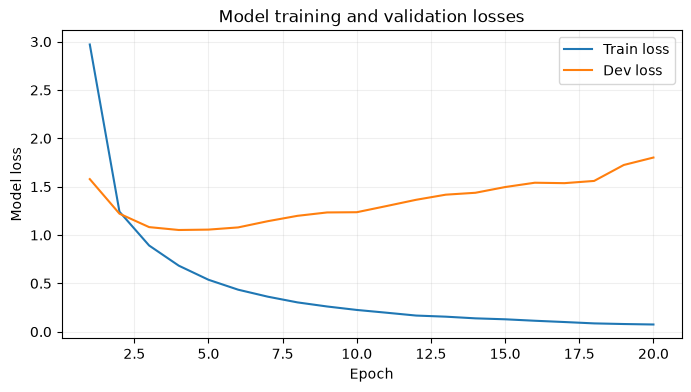

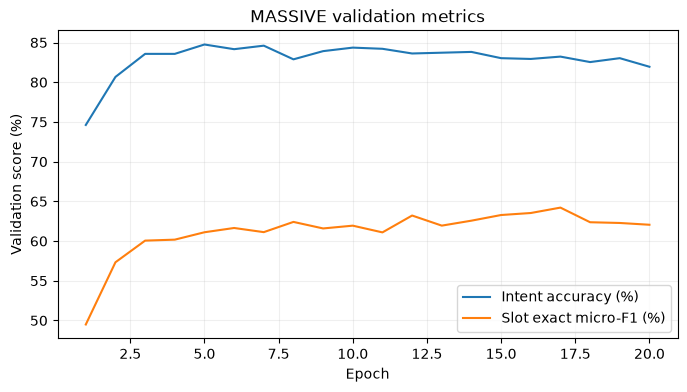

In [83]:
epoch_numbers = [x["epoch"] for x in history]
plt.figure(figsize=(8, 4))
plt.plot(epoch_numbers, [x["train_loss"] for x in history], label="Train loss")
plt.plot(epoch_numbers, [x["val_loss"] for x in history], label="Dev loss")
plt.xlabel("Epoch")
plt.ylabel("Model loss")
plt.title("Model training and validation losses")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(epoch_numbers, [x["val_intent_accuracy"] for x in history], label="Intent accuracy (%)")
plt.plot(epoch_numbers, [x["val_slot_micro_f1"] for x in history], label="Slot exact micro-F1 (%)")
plt.xlabel("Epoch")
plt.ylabel("Validation score (%)")
plt.title("MASSIVE validation metrics")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## C6: Reload Checkpoint and Final Evaluation ###

### Reload the BEST validation checkpoint and evaluate validation and test set. ###

In [84]:
checkpoint = torch.load(CHECKPOINT_PATH, weights_only=True)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

final_dev = evaluate(model, dev_loader)
final_test = evaluate(model, test_loader)
reloaded_score = (final_dev["intent_accuracy"] + final_dev["slot_micro_f1"]) / 2.0

assert abs(reloaded_score - best_score) < 1e-5, "Reloaded model score does not match best DEV score."

print(f"Best checkpoint epoch: {checkpoint['epoch']} | Seed: {checkpoint['seed']}")
print(f"Validation: intent={final_dev['intent_accuracy']:.2f}% | "
      f"slot exact micro-F1={final_dev['slot_micro_f1']:.2f}%")
print(f"Test: intent={final_test['intent_accuracy']:.2f}% | "
      f"slot exact micro-F1={final_test['slot_micro_f1']:.2f}%")
print(f"Total parameters: {total_params:,} | Trainable: {trainable_params:,}")

Best checkpoint epoch: 17 | Seed: 42
Validation: intent=83.23% | slot exact micro-F1=64.21%
Test: intent=82.25% | slot exact micro-F1=58.19%
Total parameters: 624,071 | Trainable: 624,071


## C7: Predictions ##

In [85]:
@torch.no_grad()
def show_predictions(model, data_loader, num_examples=5):
    model.eval()
    batch = next(iter(data_loader))
    intent_logits, slot_logits = model(batch["input_ids"], batch["attention_mask"])
    predicted_intents = intent_logits.argmax(dim=-1).tolist()
    predicted_tags = slot_logits.argmax(dim=-1).tolist()

    for i in range(min(num_examples, len(predicted_intents))):
        print("Utterance:", batch["utterances"][i])
        print("Predicted intent:", id_to_intent[predicted_intents[i]])
        print("Predicted slots:", decode_slot_pairs(
            predicted_tags[i], batch["utterances"][i], batch["offsets"][i]
        ))
        print()

show_predictions(model, test_loader, num_examples=5)

Utterance: wake me up at five am this week
Predicted intent: alarm_set
Predicted slots: [('time', 'five am'), ('date', 'this week')]

Utterance: quiet
Predicted intent: audio_volume_mute
Predicted slots: []

Utterance: pink is all we need
Predicted intent: iot_hue_lightchange
Predicted slots: []

Utterance: and the darkness has fallen
Predicted intent: social_query
Predicted slots: [('person', 'darkness')]

Utterance: olly turn the lights off in the bedroom
Predicted intent: iot_hue_lightoff
Predicted slots: [('house_place', 'bedroom')]



In [51]:
examples_to_check = [
    "quiet",
    "pink is all we need",
    "and the darkness has fallen",
    "olly turn the lights off in the bedroom"
]

for utterance in examples_to_check:
    matches = [
        row for row in data
        if row["utt"] == utterance
    ]

    print("\nUtterance:", utterance)

    if not matches:
        print("Not found in MASSIVE dataset")
        continue

    for row in matches:
        print("Split:", row["partition"])
        print("True intent:", row["intent"])
        print("True slots:", row["annot_utt"])


Utterance: quiet
Split: test
True intent: audio_volume_mute
True slots: quiet
Split: train
True intent: audio_volume_mute
True slots: quiet

Utterance: pink is all we need
Split: test
True intent: iot_hue_lightchange
True slots: [color_type : pink] is all we need

Utterance: and the darkness has fallen
Split: test
True intent: iot_hue_lighton
True slots: and the darkness has fallen

Utterance: olly turn the lights off in the bedroom
Split: test
True intent: iot_hue_lightoff
True slots: olly turn the lights off in the [house_place : bedroom]
